## Importando as Bibliotecas

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliotecas Importadas com Sucesso!!")

Bibliotecas Importadas com Sucesso!!


## Visão Geral dos Dados

In [4]:
dados = pd.read_csv("../data/banking_train.csv")
dados.head()

,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


In [5]:
print(f"Total de Linhas -> {len(dados)}")
print("\n=== Informações do DataSet ===")
print(dados.info())

Total de Linhas -> 10003

=== Informações do DataSet ===
<class 'pandas.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      10003 non-null  str  
 1   category  10003 non-null  str  
dtypes: str(2)
memory usage: 156.4 KB
None


In [6]:
print("=== Verificando Dados Nulos ===\n")
print(dados.isna().sum())

=== Verificando Dados Nulos ===

text        0
category    0
dtype: int64


In [7]:
print(f"Total de Dados Duplicados: {dados.duplicated().sum()}")

Total de Dados Duplicados: 0


## Verificando Distribuição das Classes

In [8]:
print(f"Total de Classes na Categoria -> {dados["category"].nunique()}")

Total de Classes na Categoria -> 77


In [9]:
classes = dados["category"].value_counts()
classes

category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
                                                   ... 
lost_or_stolen_card                                  82
card_swallowed                                       61
card_acceptance                                      59
virtual_card_not_working                             41
contactless_not_working                              35
Name: count, Length: 77, dtype: int64

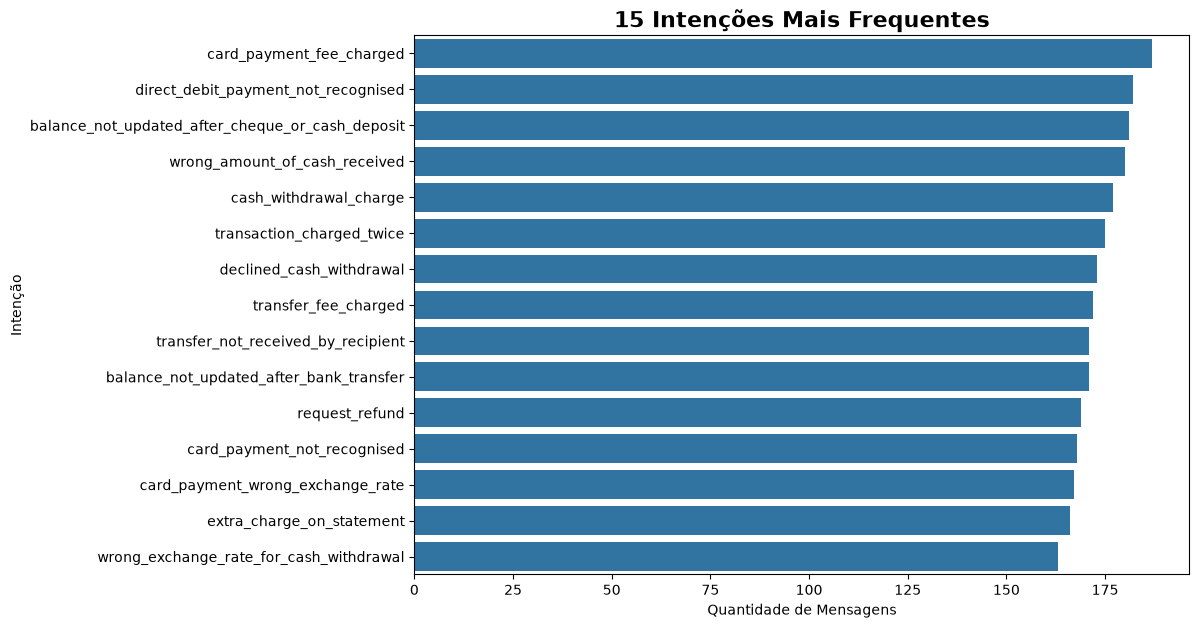

In [16]:
# Pegando a contagem das 15 classes mais frequentes
classes_15_primeiras = classes.sort_values(ascending=False).head(15)
plt.figure(figsize=(10,7))

sns.barplot(x=classes_15_primeiras.values, y=classes_15_primeiras.index)
plt.title("15 Intenções Mais Frequentes", fontsize=16, fontweight="bold")
plt.xlabel("Quantidade de Mensagens")
plt.ylabel("Intenção")
plt.show()

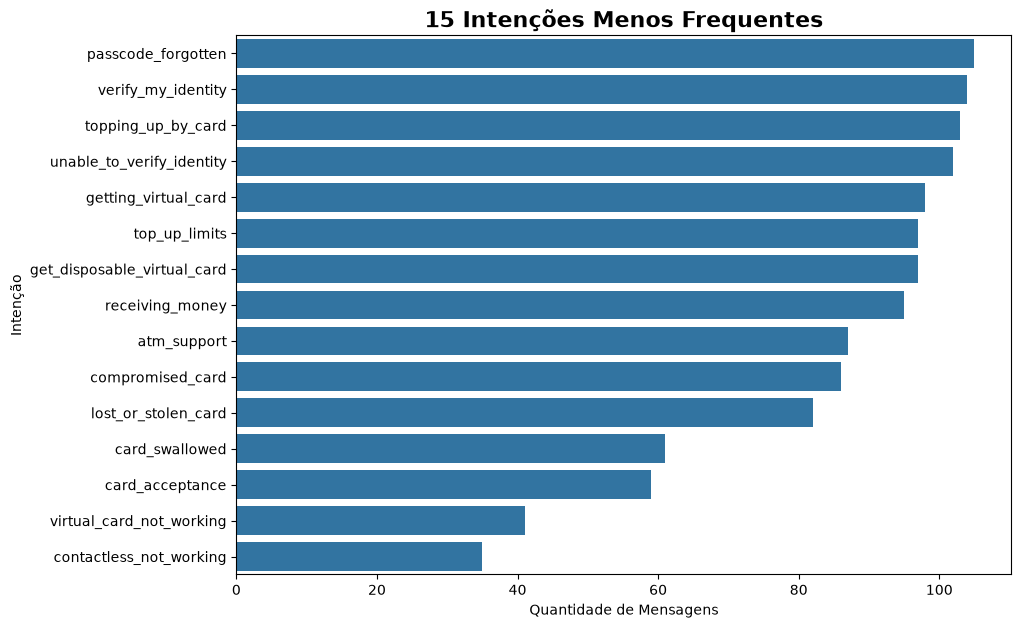

In [19]:
# Pegando a contagem das 15 classes menos frequentes
classes_15_ultimas = classes.sort_values(ascending=False).tail(15)
plt.figure(figsize=(10,7))

sns.barplot(x=classes_15_ultimas.values, y=classes_15_ultimas.index)
plt.title("15 Intenções Menos Frequentes", fontsize=16, fontweight="bold")
plt.xlabel("Quantidade de Mensagens")
plt.ylabel("Intenção")
plt.show()

## Estatísticas da Distribuição das classes

In [20]:
classes.describe()

count     77.000000
mean     129.909091
std       32.942207
min       35.000000
25%      112.000000
50%      127.000000
75%      159.000000
max      187.000000
Name: count, dtype: float64

In [24]:
print(f"Maior Classe -> {classes.max()}")
print(f"Menor Classe -> {classes.min()}")
print(f"Média -> {classes.mean():.2f}")
print(f"Mediana -> {classes.median()}")

Maior Classe -> 187
Menor Classe -> 35
Média -> 129.91
Mediana -> 127.0


## Entendendo o Vocabulário

In [26]:
from collections import Counter

In [27]:
all_words = " ".join(dados["text"]).lower().split()

word_freq = Counter(all_words)

### Pegando TOP 10 Palavras (sem StopWords)

In [29]:
# Pegando as 10 palavras mais frequentes
top_10_words = word_freq.most_common(10)

df_top_words = pd.DataFrame(
    top_10_words,
    columns=["word", "frequency"]
)
df_top_words

,word,frequency
0,i,8309
1,my,5684
2,to,4011
3,a,3565
4,the,3497
5,is,2339
6,can,1839
7,do,1730
8,card,1636
9,it,1557


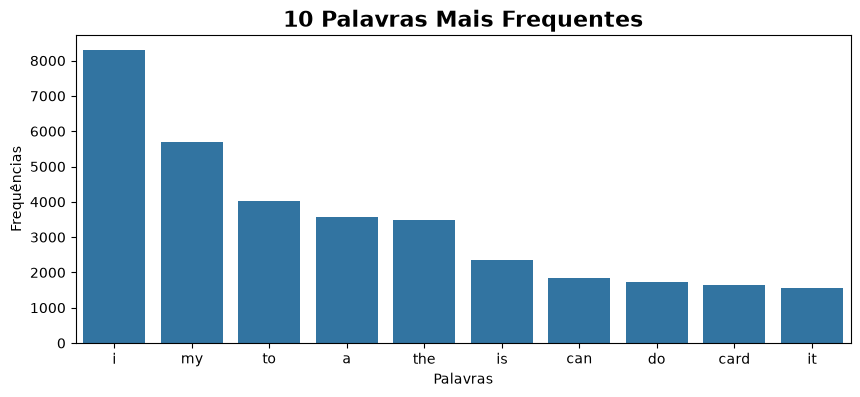

In [44]:
plt.figure(figsize=(10,4))

sns.barplot(x=df_top_words["word"], y=df_top_words["frequency"])
plt.title("10 Palavras Mais Frequentes", fontsize=16, fontweight="bold")
plt.xlabel("Palavras")
plt.ylabel("Frequências")
plt.show()

### Pegando TOP 10 palavras (com StopWords)

In [31]:
import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Unisalesiano\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [32]:
stop_words = set(stopwords.words("english"))

filtro_words = [
    word
    for word in all_words
    if word not in stop_words
]

word_freq_stop_words = Counter(filtro_words)

In [33]:
top_10_stop = word_freq_stop_words.most_common(10)

df_top_words_stop = pd.DataFrame(
    top_10_stop, columns=["word", "frequency"]
)

df_top_words_stop

,word,frequency
0,card,1636
1,money,920
2,transfer,861
3,get,796
4,need,696
5,account,684
6,card?,653
7,payment,644
8,top,609
9,cash,578


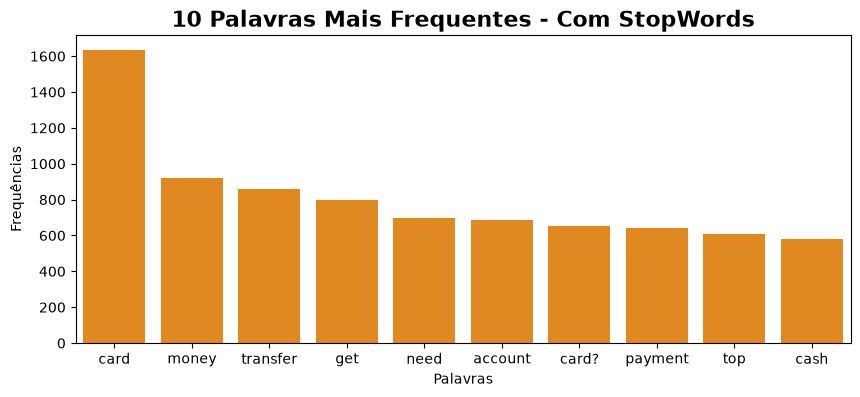

In [43]:
plt.figure(figsize=(10,4))

sns.barplot(x=df_top_words_stop["word"], y=df_top_words_stop["frequency"], color="darkorange")
plt.title("10 Palavras Mais Frequentes - Com StopWords", fontsize=16, fontweight="bold")
plt.xlabel("Palavras")
plt.ylabel("Frequências")
plt.show()

## Pegando TOP 10 Bigrams mais frequentes

In [37]:
from sklearn.feature_extraction.text import CountVectorizer

In [40]:
vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    max_features=10
)

X_bigrams = vectorizer.fit_transform(dados["text"])

bigram_freq = X_bigrams.sum(axis=0).A1

df_bigrams = pd.DataFrame({
    "bigram": vectorizer.get_feature_names_out(),
    "frequency": bigram_freq
}).sort_values("frequency", ascending=False)

df_bigrams

,bigram,frequency
3,exchange rate,293
7,new card,226
0,card payment,202
9,virtual card,181
1,cash withdrawal,165
6,money account,148
8,transfer money,118
5,long does,109
2,direct debit,102
4,extra fee,97


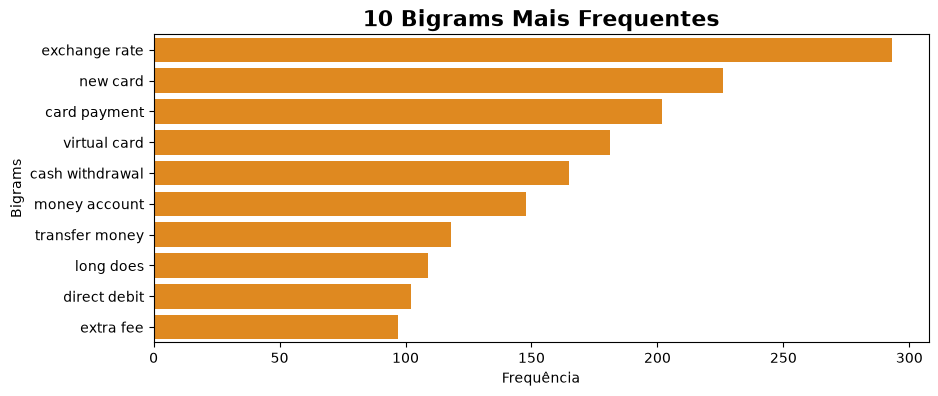

In [42]:
plt.figure(figsize=(10,4))

sns.barplot(x=df_bigrams["frequency"], y=df_bigrams["bigram"], color="darkorange")
plt.title("10 Bigrams Mais Frequentes", fontsize=16, fontweight="bold")
plt.xlabel("Frequência")
plt.ylabel("Bigrams")
plt.show()

## Analisando classes semanticamente parecidas

In [46]:
dados[dados["category"].str.contains("card")]["category"].value_counts()

category
card_payment_fee_charged            187
card_payment_not_recognised         168
card_payment_wrong_exchange_rate    167
reverted_card_payment?              161
pending_card_payment                159
activate_my_card                    159
card_arrival                        153
declined_card_payment               153
card_linking                        139
visa_or_mastercard                  135
supported_cards_and_currencies      129
getting_spare_card                  129
card_about_to_expire                129
disposable_card_limits              121
order_physical_card                 120
top_up_by_card_charge               114
card_delivery_estimate              112
card_not_working                    112
get_physical_card                   106
topping_up_by_card                  103
getting_virtual_card                 98
get_disposable_virtual_card          97
compromised_card                     86
lost_or_stolen_card                  82
card_swallowed                 

In [47]:
dados[dados["category"].str.contains("transfer")]["category"].value_counts()

category
transfer_fee_charged                       172
transfer_not_received_by_recipient         171
balance_not_updated_after_bank_transfer    171
cancel_transfer                            157
pending_transfer                           148
failed_transfer                            137
declined_transfer                          133
transfer_timing                            128
transfer_into_account                      113
top_up_by_bank_transfer_charge             111
Name: count, dtype: int64

In [48]:
dados[dados["category"].str.contains("cash")]["category"].value_counts()

category
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
declined_cash_withdrawal                            173
wrong_exchange_rate_for_cash_withdrawal             163
cash_withdrawal_not_recognised                      160
pending_cash_withdrawal                             143
top_up_by_cash_or_cheque                            114
Name: count, dtype: int64